In [69]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline

In [70]:
#Haan, bilkul! Is library se aap khud ka (synthetic) dataset bana sakte hain, aur unsupervised ML practice ke liye ye bahut common hai.
from sklearn.datasets import make_blobs

**we only use X(independent feature) In unpervised machine Learning**


In [71]:
# how many cluster u want at a time of output (centers=3)
X,y=make_blobs(n_samples=1000,centers=3,n_features=2,random_state=23) # Dataset

In [72]:
X.shape

(1000, 2)

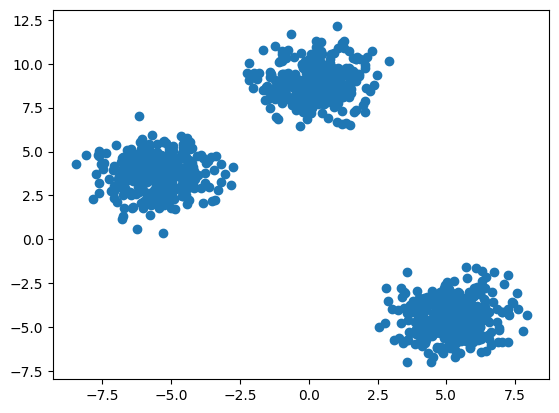

In [73]:
plt.scatter(X[:, 0], X[:, 1])

In [74]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,y, test_size=0.33,random_state=42)

**Find the value of K**

In [75]:
from sklearn.cluster import KMeans

In [76]:
## Manual process
## Elbow methods to select the k values

wcss=[]
for k in range(1,11):
  kmeans=KMeans(n_clusters=k,init='k-means++')
  kmeans.fit(x_train)
  wcss.append(kmeans.inertia_)

In [77]:
wcss

[34827.576825520235,
 7935.437286145425,
 1319.2730531585605,
 1170.867682546243,
 994.1470996184248,
 855.9402812337487,
 763.9941807483747,
 668.995941371924,
 581.6140837050289,
 535.7215707373267]

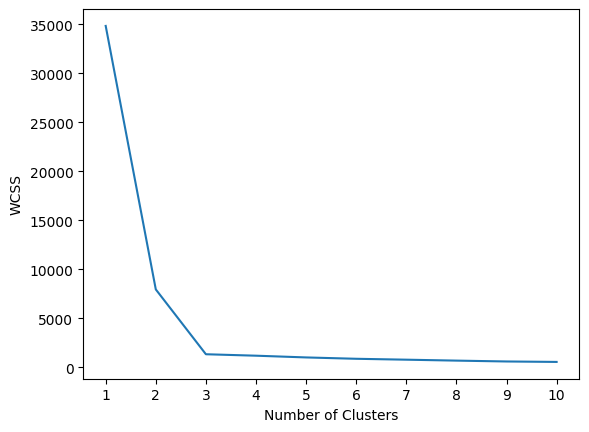

In [78]:
## plot elbow curve
plt.plot(range(1,11),wcss)
plt.xticks(range(1,11))
plt.xlabel('Number of Clusters')
plt.ylabel(wcss)
plt.show

In [79]:
kmaens=KMeans(n_clusters=3,init='k-means++')


In [80]:
# fit_predict only ham training wale dataset pe apply krtee hai
y_labels=kmaens.fit_predict(x_train)

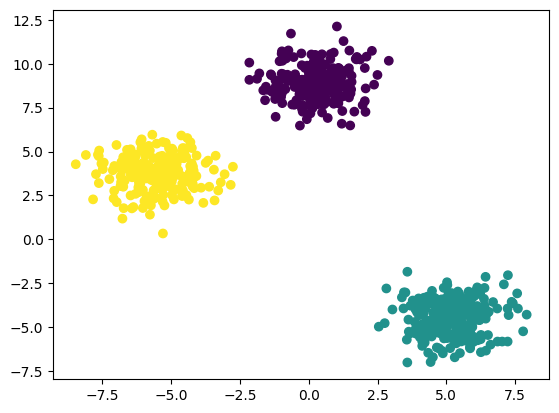

In [81]:
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_labels)

In [82]:
y_test_label=kmaens.predict(x_test)

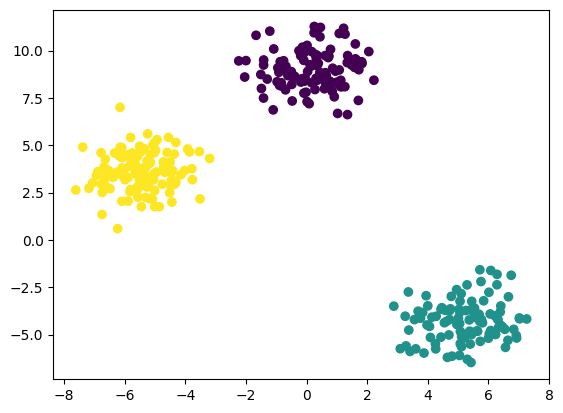

In [83]:
plt.scatter(x_test[:, 0], x_test[:, 1], c=y_test_label)

**Automate libarary to find K-values**

In [84]:
## knee Locator
! pip install kneed

In [85]:
from kneed import KneeLocator

In [86]:
k1=KneeLocator(range(1,11),wcss,curve='convex',direction='decreasing')
k1.elbow

np.int64(3)

In [87]:
## Performance matrics
## silhoutte score
from sklearn.metrics import silhouette_score

In [88]:
silhouette_coefficients=[]
for k in range(2,11):
  kmeans=KMeans(n_clusters=k,init='k-means++')
  kmeans.fit(x_train)
  score=silhouette_score(x_train,kmeans.labels_)
  silhouette_coefficients.append(score)


In [89]:
silhouette_coefficients

[np.float64(0.7281443868598331),
 np.float64(0.8071181203797672),
 np.float64(0.6578773435536361),
 np.float64(0.45978278643379306),
 np.float64(0.5010596855025912),
 np.float64(0.34575016442546685),
 np.float64(0.31061330592677394),
 np.float64(0.3322669184245678),
 np.float64(0.32812557686623534)]

<function matplotlib.pyplot.show(close=None, block=None)>

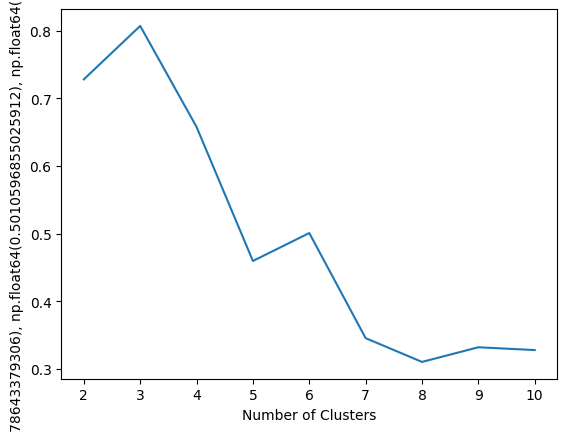

In [91]:
## plotting silhouette score
plt.plot(range(2,11),silhouette_coefficients)
# Haan, bilkul, x-axis pe sirf whole numbers (2, 3, 4, ... 10) dikhenge, koi decimal jaise 2.5 ya 3.5 nahi aayega.use of plt.xticks()
plt.xticks(range(2,11))
plt.xlabel('Number of Clusters')
plt.ylabel(silhouette_coefficients)
plt.show
